In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pickle
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

# Caricamento dati preparati
path_prepared = "/content/drive/MyDrive/Colab Notebooks/beth_prepared.pkl"

with open(path_prepared, "rb") as f:
    data = pickle.load(f)

X_train_rel = data["X_train_rel"]
X_validation_rel = data["X_validation_rel"]
X_test_rel = data["X_test_rel"]

y_train = data["y_train"]
y_validation = data["y_validation"]
y_test = data["y_test"]

event_features = data["event_features"]

# Standardizzazione: fit SOLO sul TRAIN
scaler_ae = StandardScaler()

Xs_train_ae = scaler_ae.fit_transform(X_train_rel)
Xs_validation_ae = scaler_ae.transform(X_validation_rel)
Xs_test_ae = scaler_ae.transform(X_test_rel)

print("Train:", Xs_train_ae.shape)
print("Validation:", Xs_validation_ae.shape)
print("Test:", Xs_test_ae.shape)

Train: (128, 32)
Validation: (22, 32)
Test: (13, 32)


Visto che abbiamo appena 128 finestre di training, evitiamo una rete troppo grande, che rischierebbe semplicemente di memorizzare il dataset.

Useremo una struttura:

32 → 16 → 8 → 16 → 32

dove 8 è la rappresentazione compressa (bottleneck).

32 feature in ingresso. Il modello prova a comprimere queste 32 informazioni prima a 16 valori, poi a 8 valori. Quegli 8 valori sono il bottleneck, cioè una rappresentazione compatta della finestra. Poi la rete prova a ricostruire le 32 feature originali passando di nuovo da 16 a 32.

L'idea è questa: durante il training diamo alla rete una finestra e le chiediamo di ricostruire la stessa finestra.

Il punto chiave dell'anomaly detection è l'errore di ricostruzione. Se una finestra assomiglia ai pattern che l'Autoencoder ha imparato, dovrebbe ricostruirla bene:

finestra reale       ≈ finestra ricostruita
→ errore piccolo
→ poco anomala

Se invece incontra una configurazione insolita:

finestra reale       ≠ finestra ricostruita
→ errore grande
→ più anomala


Il summary() ti dice anche quanti parametri vengono appresi. Per esempio il primo layer:

32 → 16
528 parametri

n totale la rete ha 1.352 parametri. Non è enorme, ma rispetto alle sole 128 finestre di training è comunque un modello da trattare con cautela. Per questo abbiamo scelto una struttura relativamente piccola e useremo anche early stopping invece di fissare alla cieca un numero enorme di epoche.

Per favorire la riproducibilità dell'esperimento viene fissato un seed pari a 42 per NumPy e TensorFlow/Keras. Viene inoltre abilitato, quando supportato, l'utilizzo di operazioni deterministiche in TensorFlow. Questo consente di ridurre la variabilità dovuta all'inizializzazione casuale dei pesi e alle operazioni stocastiche durante l'addestramento.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.regularizers import l2

np.random.seed(42)
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

autoencoder = Sequential([
    Input(shape=(32,)),

    Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(1e-4)
    ),

    Dense(
        8,
        activation="relu",
        name="bottleneck"
    ),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        32,
        activation="linear"
    )
])

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │           544 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,352 (5.28 KB)

 Trainable params: 1,352 (5.28 KB)

 Non-trainable params: 0 (0.00 B)

Adesso facciamo il training con EarlyStopping. Usiamo la validation solo per controllare la val_loss e fermare l'addestramento quando smette di migliorare; non usiamo le label SUS/EVIL per addestrare la rete.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = autoencoder.fit(
    Xs_train_ae,
    Xs_train_ae,
    validation_data=(Xs_validation_ae, Xs_validation_ae),
    epochs=300,
    batch_size=16,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=0
)

print("Epoche eseguite:", len(history.history["loss"]))
print("Loss finale train:", history.history["loss"][-1])
print("Loss migliore validation:", min(history.history["val_loss"]))

Epoche eseguite: 300
Loss finale train: 0.09511539340019226
Loss migliore validation: 0.4645593762397766


Nel nostro caso il training set contiene 128 finestre.

Una epoca corrisponde a un passaggio completo su tutte le 128 finestre di training. Quindi:

1 epoca = il modello utilizza tutte le 128 finestre una volta;
10 epoche = effettua 10 passaggi completi sul training set;
300 epoche = effettua 300 passaggi completi sul training set.

Poiché nel training è stato utilizzato batch_size=16, le 128 finestre non vengono elaborate tutte contemporaneamente. Il training set viene suddiviso in gruppi di 16 finestre:

$$ \frac{128}{16}=8 $$

quindi ogni epoca è composta da 8 batch e comporta 8 aggiornamenti dei parametri del modello.

Nel training definitivo l'Autoencoder ha eseguito tutte le 300 epoche previste. L'EarlyStopping non ha interrotto anticipatamente l'addestramento. La loss finale sul training è risultata pari a circa 0.0951, mentre la migliore validation loss osservata è stata circa 0.4646.

Adesso visualizziamo l'andamento dell'errore durante le 300 epoche eseguite. Il confronto tra training loss e validation loss permette di osservare il processo di apprendimento e di verificare l'eventuale comparsa di un divario crescente tra le prestazioni sul TRAIN e sulla VALIDATION.

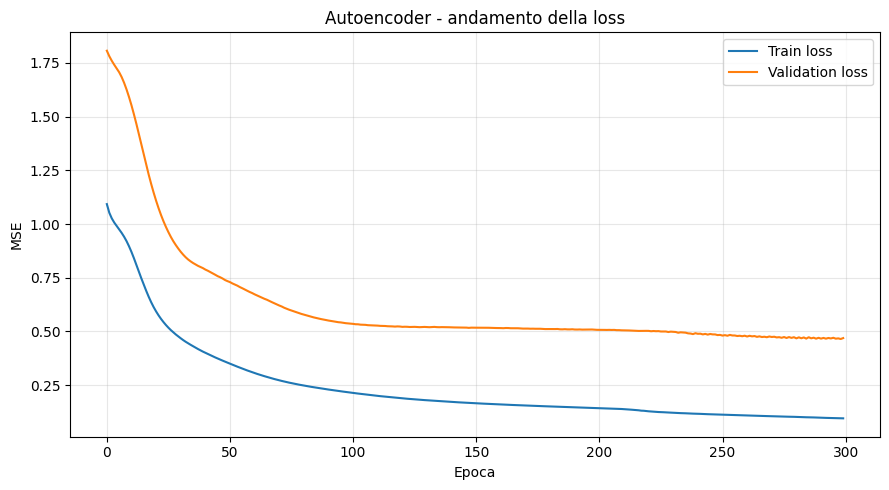

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoca")
plt.ylabel("MSE")
plt.title("Autoencoder - andamento della loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Il grafico mostra che nelle prime epoche sia la training loss sia la validation loss diminuiscono rapidamente, indicando che l'Autoencoder sta apprendendo una rappresentazione utile dei dati. Successivamente, la training loss continua a diminuire progressivamente fino a circa 0.095, mentre la validation loss si stabilizza maggiormente e migliora più lentamente, raggiungendo un minimo di circa 0.465.

Si osserva quindi un divario crescente tra TRAIN e VALIDATION: il modello ricostruisce le finestre utilizzate per l'addestramento sensibilmente meglio rispetto alle finestre non utilizzate per l'ottimizzazione dei pesi. Questo comportamento costituisce un segnale di possibile overfitting o, più precisamente, di un generalization gap e deve essere tenuto in considerazione nell'interpretazione dei risultati.

Tuttavia, la validation loss non mostra una crescita marcata nelle ultime epoche e continua a presentare piccoli miglioramenti. Per questo motivo l'EarlyStopping, configurato con patience=20, non ha interrotto anticipatamente il training e sono state completate tutte le 300 epoche previste. Grazie a restore_best_weights=True, al termine del training vengono comunque mantenuti i pesi corrispondenti alla migliore validation loss osservata.

trasformiamo l'Autoencoder in un anomaly detector calcolando l'errore di ricostruzione di ogni finestra.

Qui non c'è ancora nessuna soglia e nessuna label coinvolta:

$$ \text{anomaly score} = \frac{1}{32}\sum_{j=1}^{32}(x_j-\hat{x}_j)^2 $$

MSE basso = ricostruzione buona = finestra più simile ai pattern appresi.
MSE alto = ricostruzione difficile = finestra più anomala.

In [ ]:
# Ricostruzioni definitive
X_train_pred_ae = autoencoder.predict(
    Xs_train_ae, verbose=0
)

X_validation_pred_ae = autoencoder.predict(
    Xs_validation_ae, verbose=0
)

X_test_pred_ae = autoencoder.predict(
    Xs_test_ae, verbose=0
)

# MSE di ricostruzione per ogni finestra
anomaly_score_train_ae = np.mean(
    (Xs_train_ae - X_train_pred_ae) ** 2,
    axis=1
)

anomaly_score_validation_ae = np.mean(
    (Xs_validation_ae - X_validation_pred_ae) ** 2,
    axis=1
)

anomaly_score_test_ae = np.mean(
    (Xs_test_ae - X_test_pred_ae) ** 2,
    axis=1
)

print("Anomaly score TEST:")

for i, score in enumerate(anomaly_score_test_ae):
    print(f"Window {i}: {score:.6f}")

Anomaly score TEST:
Window 0: 11.216333
Window 1: 1.464183
Window 2: 0.004511
Window 3: 0.038555
Window 4: 0.009610
Window 5: 301.294378
Window 6: 0.017900
Window 7: 5.327684
Window 8: 0.490049
Window 9: 10.338479
Window 10: 12.550490
Window 11: 167.767700
Window 12: 157.788093


Gli anomaly score dell'Autoencoder sono definiti come errore quadratico medio di ricostruzione per ciascuna finestra. Valori più elevati indicano finestre che il modello ricostruisce con maggiore difficoltà e che risultano quindi più anomale rispetto ai pattern appresi sul TRAIN.

Nel TEST, gli score più elevati sono osservati per le finestre 5 (301.294), 11 (167.768) e 12 (157.788). Anche le finestre 0, 9 e 10 presentano reconstruction error elevati, rispettivamente pari a circa 11.216, 10.338 e 12.550.

È importante ricordare che questi score sono prodotti in modo unsupervised: un valore elevato indica distanza rispetto ai pattern ricostruiti dal modello, ma non implica automaticamente che la finestra sia etichettata SUS o EVIL. Per esempio, la finestra 5 presenta lo score più elevato pur non appartenendo a nessuna delle due classi positive.

Ora misuriamo formalmente quanto bene il ranking degli score separa SUS ed EVIL usando la ROC-AUC. Non scegliamo ancora nessuna soglia.

In [ ]:
from sklearn.metrics import roc_auc_score

y_test_sus = y_test["sus_window"].astype(int).values
y_test_evil = y_test["evil_window"].astype(int).values

auc_sus_ae = roc_auc_score(
    y_test_sus,
    anomaly_score_test_ae
)

auc_evil_ae = roc_auc_score(
    y_test_evil,
    anomaly_score_test_ae
)

print(f"AUC SUS  Autoencoder: {auc_sus_ae:.3f}")
print(f"AUC EVIL Autoencoder: {auc_evil_ae:.3f}")

AUC SUS  Autoencoder: 0.667
AUC EVIL Autoencoder: 0.875


| Modello           |   AUC SUS |  AUC EVIL |
| ----------------- | --------: | --------: |
| Isolation Forest  |     0.643 |     0.825 |
| LOF               |     0.548 |     0.825 |
| **One-Class SVM** | **0.690** | **0.900** |
| Autoencoder       |     0.667 |     0.875 |


Sul TEST disponibile, la One-Class SVM presenta l'AUC più elevata per entrambe le label (0.690 per SUS e 0.900 per EVIL), mentre l'Autoencoder ottiene il secondo valore più elevato (0.667 per SUS e 0.875 per EVIL). Tuttavia, considerando che il TEST contiene soltanto 13 finestre, queste differenze devono essere interpretate con cautela e non sono sufficienti per concludere che un modello sia generalmente superiore agli altri. Il confronto verrà completato considerando anche il comportamento alle soglie, gli errori sulle singole finestre e l'ensemble.

Ora facciamo il grafico ROC dell'Autoencoder

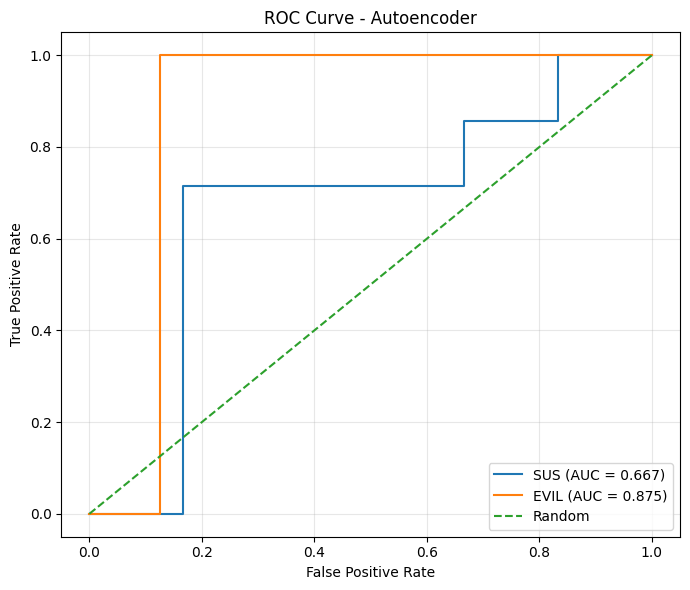

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# ROC SUS
fpr_sus, tpr_sus, _ = roc_curve(
    y_test_sus,
    anomaly_score_test_ae
)

# ROC EVIL
fpr_evil, tpr_evil, _ = roc_curve(
    y_test_evil,
    anomaly_score_test_ae
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_sus,
    tpr_sus,
    label=f"SUS (AUC = {auc_sus_ae:.3f})"
)

plt.plot(
    fpr_evil,
    tpr_evil,
    label=f"EVIL (AUC = {auc_evil_ae:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Autoencoder")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Il grafico è coerente con gli AUC appena calcolati. La curva EVIL (arancione) raggiunge rapidamente valori elevati di TPR, indicando che il ranking prodotto dall'Autoencoder separa piuttosto bene le finestre EVIL da quelle non EVIL. La curva SUS (blu) mostra invece una capacità discriminante più moderata, coerentemente con AUC SUS = 0.667, rispetto a AUC EVIL = 0.875.

calcoliamo le soglie candidate dal TRAIN

In [ ]:
percentili = [90, 95, 97, 99]

thresholds_ae = {
    p: np.percentile(anomaly_score_train_ae, p)
    for p in percentili
}

print("Soglie candidate Autoencoder:")

for p, threshold in thresholds_ae.items():
    print(f"{p}% -> {threshold:.6f}")

Soglie candidate Autoencoder:
90% -> 0.226207
95% -> 0.334281
97% -> 0.630649
99% -> 0.931533


Ora facciamo la selezione della soglia SUS sulla validation, esattamente come per gli altri modelli. Nella validation ci sono solo 2 finestre SUS positive (0 e 21), quindi qualsiasi scelta sarà necessariamente poco robusta.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

y_val_sus = y_validation["sus_window"].astype(int).values

for p, threshold in thresholds_ae.items():

    pred_val_sus = (
        anomaly_score_validation_ae >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_sus, pred_val_sus, zero_division=0
    )

    recall = recall_score(
        y_val_sus, pred_val_sus, zero_division=0
    )

    f1 = f1_score(
        y_val_sus, pred_val_sus, zero_division=0
    )

    finestre_anomale = np.where(pred_val_sus == 1)[0]

    print(
        f"{p}% | soglia={threshold:.6f} | "
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )

    print("Finestre segnalate:", finestre_anomale)
    print()

print("Finestre SUS reali:", np.where(y_val_sus == 1)[0])

90% | soglia=0.226207 | Precision=0.143 | Recall=0.500 | F1=0.222
Finestre segnalate: [ 5  6 10 11 16 20 21]

95% | soglia=0.334281 | Precision=0.000 | Recall=0.000 | F1=0.000
Finestre segnalate: [ 6 10 11 16 20]

97% | soglia=0.630649 | Precision=0.000 | Recall=0.000 | F1=0.000
Finestre segnalate: [ 6 10]

99% | soglia=0.931533 | Precision=0.000 | Recall=0.000 | F1=0.000
Finestre segnalate: [10]

Finestre SUS reali: [ 0 21]


Tra le quattro soglie candidate, il 90° percentile è l'unico che riesce a rilevare almeno una delle due finestre SUS presenti nella VALIDATION.

Con la soglia 0.226207, l'Autoencoder segnala le finestre [5, 6, 10, 11, 16, 20, 21]. Poiché le finestre realmente SUS sono [0, 21], viene rilevata correttamente la finestra 21, mentre la finestra 0 non viene identificata. Le altre sei finestre segnalate costituiscono falsi positivi. Si ottengono quindi Precision = 0.143, Recall = 0.500 e F1 = 0.222.

Le soglie corrispondenti al 95°, 97° e 99° percentile non rilevano nessuna delle due finestre SUS e producono quindi Recall = 0 e F1 = 0.

In base al protocollo adottato, viene pertanto selezionata per SUS la soglia:

Soglia SUS Autoencoder = 0.226207 (90° percentile)

La scelta deve tuttavia essere interpretata con particolare cautela, poiché la VALIDATION contiene soltanto 2 finestre SUS positive. La selezione è coerente con il protocollo sperimentale adottato, ma statisticamente fragile.

In [ ]:
selected_percentile_sus_ae = 90
selected_threshold_sus_ae = thresholds_ae[
    selected_percentile_sus_ae
]

print(
    "Percentile SUS selezionato:",
    selected_percentile_sus_ae
)

print(
    f"Soglia SUS selezionata: "
    f"{selected_threshold_sus_ae:.6f}"
)

Percentile SUS selezionato: 90
Soglia SUS selezionata: 0.226207


Adesso fissiamola e valutiamola sul TEST.

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Soglia selezionata esclusivamente sulla validation
soglia_sus_ae = thresholds_ae[90]

pred_test_sus_ae = (
    anomaly_score_test_ae >= soglia_sus_ae
).astype(int)

cm_sus_ae = confusion_matrix(
    y_test_sus,
    pred_test_sus_ae
)

precision_sus_ae = precision_score(
    y_test_sus,
    pred_test_sus_ae,
    zero_division=0
)

recall_sus_ae = recall_score(
    y_test_sus,
    pred_test_sus_ae,
    zero_division=0
)

f1_sus_ae = f1_score(
    y_test_sus,
    pred_test_sus_ae,
    zero_division=0
)

print(f"Soglia SUS: {soglia_sus_ae:.6f}")
print(
    "Finestre SUS predette:",
    np.where(pred_test_sus_ae == 1)[0]
)

print("\nConfusion matrix:")
print(cm_sus_ae)

print(f"\nPrecision: {precision_sus_ae:.3f}")
print(f"Recall:    {recall_sus_ae:.3f}")
print(f"F1:        {f1_sus_ae:.3f}")

Soglia SUS: 0.226207
Finestre SUS predette: [ 0  1  5  7  8  9 10 11 12]

Confusion matrix:
[[2 4]
 [2 5]]

Precision: 0.556
Recall:    0.714
F1:        0.625


Applicando al TEST la soglia SUS selezionata sulla VALIDATION (0.226207, corrispondente al 90° percentile del TRAIN), l'Autoencoder segnala come anomale le finestre [0, 1, 5, 7, 8, 9, 10, 11, 12].

Delle 7 finestre realmente SUS ([0, 3, 4, 9, 10, 11, 12]), il modello ne identifica correttamente 5 ([0, 9, 10, 11, 12]), mentre non rileva le finestre 3 e 4. Vengono inoltre segnalate erroneamente quattro finestre non-SUS ([1, 5, 7, 8]).

La confusion matrix è quindi [[2, 4], [2, 5]], con Precision = 0.556, Recall = 0.714 e F1 = 0.625.

L'Autoencoder mostra quindi una buona capacità di intercettare le finestre SUS del TEST, a fronte di una precisione più contenuta dovuta alla presenza di falsi positivi. Il risultato deve comunque essere interpretato considerando la dimensione molto ridotta del TEST e la fragilità della selezione della soglia sulla VALIDATION.

Ora facciamo EVIL. Qui non selezioniamo una soglia, perché nella validation non esiste nessuna finestra EVIL positiva. Valutiamo quindi sul TEST le quattro soglie derivate dal TRAIN solo a scopo esplorativo:

In [ ]:
y_test_evil = (
    y_test["evil_window"]
    .astype(int)
    .values
)

print("Finestre EVIL reali:")
print(np.where(y_test_evil == 1)[0])

for p, threshold in thresholds_ae.items():

    pred_test_evil = (
        anomaly_score_test_ae > threshold
    ).astype(int)

    precision = precision_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    recall = recall_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    f1 = f1_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    print(f"\n--- {p}% | soglia={threshold:.6f} ---")
    print(
        "Finestre segnalate:",
        np.where(pred_test_evil == 1)[0]
    )
    print(
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )

Finestre EVIL reali:
[ 0  9 10 11 12]

--- 90% | soglia=0.226207 ---
Finestre segnalate: [ 0  1  5  7  8  9 10 11 12]
Precision=0.556 | Recall=1.000 | F1=0.714

--- 95% | soglia=0.334281 ---
Finestre segnalate: [ 0  1  5  7  8  9 10 11 12]
Precision=0.556 | Recall=1.000 | F1=0.714

--- 97% | soglia=0.630649 ---
Finestre segnalate: [ 0  1  5  7  9 10 11 12]
Precision=0.625 | Recall=1.000 | F1=0.769

--- 99% | soglia=0.931533 ---
Finestre segnalate: [ 0  1  5  7  9 10 11 12]
Precision=0.625 | Recall=1.000 | F1=0.769


L'Autoencoder mostra una buona capacità di rilevare le finestre EVIL del TEST: tutte e 5 le finestre EVIL reali [0, 9, 10, 11, 12] vengono identificate a tutte e quattro le soglie considerate, ottenendo quindi Recall = 1.000 in ogni caso.

Alle soglie del 90° e 95° percentile vengono segnalate 9 finestre, con Precision = 0.556 e F1 = 0.714. Alle soglie del 97° e 99° percentile vengono invece segnalate 8 finestre: le cinque EVIL e tre falsi positivi ([1, 5, 7]), ottenendo Precision = 0.625 e F1 = 0.769.

Questi risultati devono essere considerati esclusivamente esplorativi. Poiché la VALIDATION non contiene finestre EVIL positive, non è possibile selezionare o ottimizzare una soglia EVIL mediante il protocollo adottato. Pertanto, nel risultato finale dell'Autoencoder la soglia EVIL rimane None; le prestazioni osservate sul TEST non vengono utilizzate per la selezione della soglia.

Ora analizziamo la sensibilità dell'Autoencoder rispetto alle singole feature. Per ciascuna feature permutiamo i suoi valori nella VALIDATION, mantenendo inalterate le altre feature, e misuriamo quanto cambia l'anomaly score rispetto agli score originali. Ripetendo la permutazione più volte possiamo stimare sia l'effetto medio sia la sua variabilità.

Questa analisi fornisce una misura di sensibilità globale del modello alle feature sulla VALIDATION e non deve essere interpretata come una spiegazione causale delle singole anomalie.

In [ ]:
rng = np.random.default_rng(42)

n_repeats = 30
feature_sensitivity_ae = {}

baseline_scores_ae = anomaly_score_validation_ae.copy()

for j, feature in enumerate(event_features):

    changes = []

    for _ in range(n_repeats):

        X_perm = Xs_validation_ae.copy()

        X_perm[:, j] = rng.permutation(
            X_perm[:, j]
        )

        X_perm_pred = autoencoder.predict(
            X_perm,
            verbose=0
        )

        perm_scores = np.mean(
            (X_perm - X_perm_pred) ** 2,
            axis=1
        )

        changes.append(
            np.mean(
                np.abs(
                    perm_scores - baseline_scores_ae
                )
            )
        )

    feature_sensitivity_ae[feature] = {
        "mean": np.mean(changes),
        "std": np.std(changes)
    }

sensitivity_sorted_ae = sorted(
    feature_sensitivity_ae.items(),
    key=lambda x: x[1]["mean"],
    reverse=True
)

print("Top 10 feature per sensitivity - Autoencoder (VALIDATION):")

for feature, values in sensitivity_sorted_ae[:10]:
    print(
        f"{feature:30s} "
        f"{values['mean']:.6f} ± "
        f"{values['std']:.6f}"
    )

Top 10 feature per sensitivity - Autoencoder (VALIDATION):
security_inode_unlink          0.663136 ± 0.108776
unlink                         0.254543 ± 0.048516
access                         0.210931 ± 0.044806
lstat                          0.187227 ± 0.042804
security_file_open             0.127658 ± 0.033892
openat                         0.124098 ± 0.024416
socket                         0.106104 ± 0.035104
getdents64                     0.104772 ± 0.028576
stat                           0.093352 ± 0.015294
sched_process_exit             0.075159 ± 0.016426


L'analisi di sensitivity sulla VALIDATION mostra che security_inode_unlink produce la variazione media più elevata dell'anomaly score (0.663 ± 0.109), risultando nettamente più influente delle altre feature secondo questa misura. Seguono unlink (0.255 ± 0.049), access (0.211 ± 0.045) e lstat (0.187 ± 0.043).

Tra le feature maggiormente sensibili compaiono inoltre security_file_open, openat, socket, getdents64, stat e sched_process_exit.

Questi risultati descrivono una sensibilità globale dell'Autoencoder alle perturbazioni delle singole feature sulla VALIDATION. Non costituiscono una spiegazione causale delle predizioni e non implicano che le stesse feature siano necessariamente responsabili dell'elevato anomaly score di ogni singola finestra.

Ora facciamo il grafico top-10, mantenendo lo stesso formato degli altri modelli:

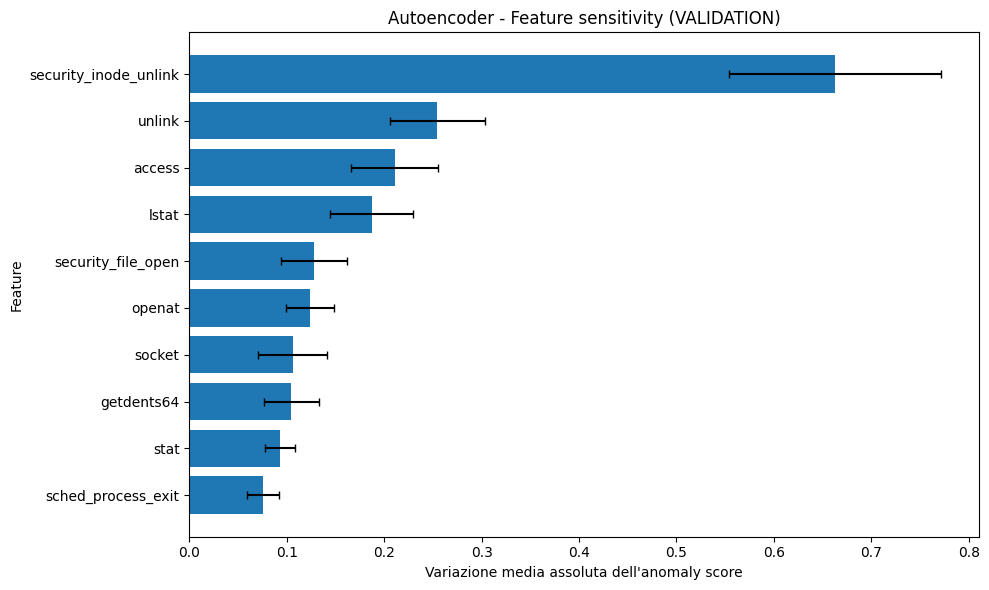

In [ ]:
import matplotlib.pyplot as plt

top10_features_ae = [
    feature
    for feature, _ in sensitivity_sorted_ae[:10]
]

top10_means_ae = [
    feature_sensitivity_ae[f]["mean"]
    for f in top10_features_ae
]

top10_stds_ae = [
    feature_sensitivity_ae[f]["std"]
    for f in top10_features_ae
]

plt.figure(figsize=(10, 6))

plt.barh(
    top10_features_ae[::-1],
    top10_means_ae[::-1],
    xerr=top10_stds_ae[::-1],
    capsize=3
)

plt.xlabel("Variazione media assoluta dell'anomaly score")
plt.ylabel("Feature")
plt.title(
    "Autoencoder - Feature sensitivity (VALIDATION)"
)

plt.tight_layout()
plt.show()

Ora facciamo il profilo delle top-10 feature sulle 13 finestre TEST, come abbiamo fatto per OCSVM.

Usiamo X_test_rel, quindi valori originali interpretabili.

In [ ]:
sensibilita_ae_df = pd.DataFrame([
    {
        "feature": feature,
        "mean_sensitivity": values["mean"],
        "std_sensitivity": values["std"]
    }
    for feature, values in sensitivity_sorted_ae
])

print("Shape sensitivity:", sensibilita_ae_df.shape)
display(sensibilita_ae_df.head(10))

Shape sensitivity: (32, 3)


,feature,mean_sensitivity,std_sensitivity
0,security_inode_unlink,0.663136,0.108776
1,unlink,0.254543,0.048516
2,access,0.210931,0.044806
3,lstat,0.187227,0.042804
4,security_file_open,0.127658,0.033892
5,openat,0.124098,0.024416
6,socket,0.106104,0.035104
7,getdents64,0.104772,0.028576
8,stat,0.093352,0.015294
9,sched_process_exit,0.075159,0.016426


In [ ]:
# Top 10 feature secondo la sensitivity AE sulla VALIDATION
top10_features_ae = (
    sensibilita_ae_df
    .head(10)["feature"]
    .tolist()
)

# Profilo TEST usando le frequenze relative originali
if hasattr(X_test_rel, "loc"):
    test_profile_ae = X_test_rel[
        top10_features_ae
    ].copy()
else:
    top10_idx_ae = [
        list(event_features).index(feature)
        for feature in top10_features_ae
    ]

    test_profile_ae = pd.DataFrame(
        X_test_rel[:, top10_idx_ae],
        columns=top10_features_ae
    )

# Aggiungiamo score e label reali
test_profile_ae.insert(
    0, "EVIL_reale",
    y_test["evil_window"].astype(int).values
)

test_profile_ae.insert(
    0, "SUS_reale",
    y_test["sus_window"].astype(int).values
)

test_profile_ae.insert(
    0, "anomaly_score_ae",
    anomaly_score_test_ae
)

test_profile_ae.insert(
    0, "window",
    range(len(test_profile_ae))
)

print(test_profile_ae.to_string(index=False))

 window  anomaly_score_ae  SUS_reale  EVIL_reale  security_inode_unlink   unlink   access    lstat  security_file_open   openat   socket  getdents64     stat  sched_process_exit
      0         11.216333          1           1               0.008465 0.004938 0.007054 0.029626            0.172584 0.221961 0.010816    0.033858 0.042323            0.002822
      1          1.464183          0           0               0.000000 0.000000 0.000000 0.000000            0.142857 0.142857 0.142857    0.000000 0.000000            0.000000
      2          0.004511          0           0               0.000000 0.000000 0.000861 0.000000            0.287435 0.292599 0.000861    0.001721 0.090361            0.000861
      3          0.038555          1           0               0.000000 0.000000 0.004348 0.001449            0.166667 0.176812 0.037681    0.028986 0.015942            0.000000
      4          0.009610          1           0               0.000000 0.000000 0.000810 0.000000            

Il confronto tra gli anomaly score e le feature globalmente più sensibili evidenzia che la sensitivity globale non costituisce una spiegazione locale delle singole anomalie.

La finestra 5, ad esempio, presenta l'anomaly score più elevato dell'intero TEST (301.294) pur avendo valore nullo in 9 delle 10 feature mostrate; tra queste, soltanto sched_process_exit assume un valore elevato (0.333333). Analogamente, le finestre 11 e 12 presentano reconstruction error molto elevati (167.768 e 157.788) nonostante molte delle feature globalmente più sensibili abbiano valori nulli o molto piccoli.

Questo comportamento è compatibile con la natura multivariata dell'Autoencoder: l'anomaly score dipende dalla ricostruzione congiunta di tutte le 32 feature e può quindi essere determinato da feature non presenti nella top-10, da combinazioni tra feature o da configurazioni complessive poco rappresentate nel TRAIN.

Si osserva inoltre che le finestre SUS 3 e 4 hanno anomaly score molto bassi (0.0386 e 0.0096) e non vengono rilevate dalla soglia SUS selezionata. Al contrario, la finestra 5 presenta uno score estremamente elevato pur non essendo etichettata né SUS né EVIL. Questo evidenzia che il concetto di anomalia appreso in modo unsupervised non coincide necessariamente con le label disponibili.

In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np

y_test_sus = y_test["sus_window"].astype(int).values
y_test_evil = y_test["evil_window"].astype(int).values

# AUC dell'Autoencoder attualmente presente nel runtime
auc_sus_ae_check = roc_auc_score(
    y_test_sus,
    anomaly_score_test_ae
)

auc_evil_ae_check = roc_auc_score(
    y_test_evil,
    anomaly_score_test_ae
)

# Soglie corrispondenti agli score TRAIN attuali
thresholds_ae_check = {
    p: np.percentile(anomaly_score_train_ae, p)
    for p in [90, 95, 97, 99]
}

print(f"AUC SUS attuale:  {auc_sus_ae_check:.6f}")
print(f"AUC EVIL attuale: {auc_evil_ae_check:.6f}")

print("\nSoglie TRAIN attuali:")
for p, t in thresholds_ae_check.items():
    print(f"{p}% -> {t:.6f}")

AUC SUS attuale:  0.666667
AUC EVIL attuale: 0.875000

Soglie TRAIN attuali:
90% -> 0.226207
95% -> 0.334281
97% -> 0.630649
99% -> 0.931533


In [ ]:
import pickle

ae_results = {
    "model": autoencoder,
    "scaler": scaler_ae,

    "anomaly_score_train": anomaly_score_train_ae,
    "anomaly_score_validation": anomaly_score_validation_ae,
    "anomaly_score_test": anomaly_score_test_ae,

    "auc_sus": auc_sus_ae,
    "auc_evil": auc_evil_ae,

    "thresholds_train": thresholds_ae,

    "threshold_selection": {
        "SUS": {
            "threshold": selected_threshold_sus_ae,
            "percentile": selected_percentile_sus_ae,
            "criterion": "max F1 on validation",
            "precision_validation": 0.143,
            "recall_validation": 0.500,
            "f1_validation": 0.222,
            "note": (
                "Selezione fragile: la validation contiene "
                "solo 2 finestre SUS positive."
            )
        },

        "EVIL": {
            "threshold": None,
            "percentile": None,
            "criterion": None,
            "note": (
                "Nessuna soglia EVIL selezionata: "
                "la validation non contiene finestre EVIL positive."
            )
        }
    },

    "feature_sensitivity": sensibilita_ae_df,

    # NUOVE INFORMAZIONI
    "sensitivity_dataset": "validation",
    "sensitivity_repeats": 30,

    "top10_features": top10_features_ae,
    "test_feature_profiles": test_profile_ae,

    "architecture": {
        "input_dim": 32,
        "encoder": [16, 8],
        "decoder": [16, 32],
        "bottleneck_dim": 8,
        "loss": "mse",
        "optimizer": "adam"
    },

    "training": {
        "epochs_executed": len(history.history["loss"]),
        "batch_size": 16,
        "final_train_loss": history.history["loss"][-1],
        "best_validation_loss": min(history.history["val_loss"]),
        "loss_history": history.history["loss"],
        "val_loss_history": history.history["val_loss"],
        "seed": 42,
        "deterministic_ops": True
    }
}

path_ae = "/content/drive/MyDrive/Colab Notebooks/autoencoder_results.pkl"

with open(path_ae, "wb") as f:
    pickle.dump(ae_results, f)

print("Salvato in:")
print(path_ae)

print("\nChiavi salvate:")
print(list(ae_results.keys()))

Salvato in:
/content/drive/MyDrive/Colab Notebooks/autoencoder_results.pkl

Chiavi salvate:
['model', 'scaler', 'anomaly_score_train', 'anomaly_score_validation', 'anomaly_score_test', 'auc_sus', 'auc_evil', 'thresholds_train', 'threshold_selection', 'feature_sensitivity', 'sensitivity_dataset', 'sensitivity_repeats', 'top10_features', 'test_feature_profiles', 'architecture', 'training']


In [ ]:
import pickle

path_ae = "/content/drive/MyDrive/Colab Notebooks/autoencoder_results.pkl"

with open(path_ae, "rb") as f:
    ae_results_check = pickle.load(f)

print("Chiavi caricate:")
print(list(ae_results_check.keys()))

print("\nSensitivity dataset:")
print(ae_results_check["sensitivity_dataset"])

print("\nSensitivity repeats:")
print(ae_results_check["sensitivity_repeats"])

print("\nAUC:")
print("SUS :", ae_results_check["auc_sus"])
print("EVIL:", ae_results_check["auc_evil"])

print("\nSoglia SUS:")
print(ae_results_check["threshold_selection"]["SUS"])

print("\nTraining:")
print("Epoche:", ae_results_check["training"]["epochs_executed"])
print("Seed:", ae_results_check["training"]["seed"])
print(
    "Deterministic ops:",
    ae_results_check["training"]["deterministic_ops"]
)

Chiavi caricate:
['model', 'scaler', 'anomaly_score_train', 'anomaly_score_validation', 'anomaly_score_test', 'auc_sus', 'auc_evil', 'thresholds_train', 'threshold_selection', 'feature_sensitivity', 'sensitivity_dataset', 'sensitivity_repeats', 'top10_features', 'test_feature_profiles', 'architecture', 'training']

Sensitivity dataset:
validation

Sensitivity repeats:
30

AUC:
SUS : 0.6666666666666666
EVIL: 0.875

Soglia SUS:
{'threshold': np.float64(0.2262074774510426), 'percentile': 90, 'criterion': 'max F1 on validation', 'precision_validation': 0.143, 'recall_validation': 0.5, 'f1_validation': 0.222, 'note': 'Selezione fragile: la validation contiene solo 2 finestre SUS positive.'}

Training:
Epoche: 300
Seed: 42
Deterministic ops: True
